# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

**Sinh viên:** Nguyễn Việt Tiến - **MSSV:** 24521777

Notebook chạy trên Google Colab (Runtime -> Change runtime type -> T4 GPU). Cả 4 bài dùng chung một phép chia train/val/test với seed 42.

In [28]:
import os, time, copy, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, f1_score)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch :", torch.__version__)
print("device:", device)

torch : 2.11.0+cu130
device: cuda


## Chuẩn bị dữ liệu VinaFood21

In [29]:
# Tải và giải nén dữ liệu (chỉ chạy lần đầu)
FILE_ID = "1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR"
ZIP_PATH = Path("VinaFood21.zip")
RAW_DIR = Path("VinaFood21_raw")

if not RAW_DIR.exists():
    if not ZIP_PATH.exists():
        import gdown
        gdown.download(id=FILE_ID, output=str(ZIP_PATH), quiet=False)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)

# Tìm thư mục chứa train/ và test/ (file zip có thể lồng thêm một cấp thư mục)
def find_root(base):
    for p in [base] + sorted(base.rglob("*")):
        if p.is_dir() and (p / "train").is_dir() and (p / "test").is_dir():
            return p
    raise FileNotFoundError("Không tìm thấy thư mục có train/ và test/")

SRC_ROOT = find_root(RAW_DIR)
print("Thư mục dữ liệu gốc:", SRC_ROOT)

Thư mục dữ liệu gốc: VinaFood21_raw/VinaFood21


In [30]:
# Ảnh gốc khá lớn nên đọc mỗi epoch rất chậm.
# Resize trước một lần (cạnh ngắn = 256) để các bài sau load nhanh hơn, 224 vẫn đủ cho Bài 4.
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

DATA_ROOT = Path("VinaFood21_256")
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def shrink(args):
    src, dst = args
    if dst.exists():
        return 1
    try:
        img = Image.open(src).convert("RGB")
        w, h = img.size
        s = 256 / min(w, h)
        if s < 1:
            img = img.resize((round(w * s), round(h * s)), Image.BILINEAR)
        dst.parent.mkdir(parents=True, exist_ok=True)
        img.save(dst.with_suffix(".jpg"), quality=92)
        return 1
    except Exception:
        return 0          # bỏ qua ảnh lỗi

jobs = []
for split in ["train", "test"]:
    for f in (SRC_ROOT / split).rglob("*"):
        if f.suffix.lower() in EXTS:
            jobs.append((f, (DATA_ROOT / f.relative_to(SRC_ROOT)).with_suffix(".jpg")))

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    ok = sum(ex.map(shrink, jobs))
print(f"Đã xử lý {ok}/{len(jobs)} ảnh trong {time.time() - t0:.0f}s")

Đã xử lý 16726/16726 ảnh trong 1s


In [31]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SEED = 42
VAL_RATIO = 0.1
NUM_WORKERS = 2

def build_tf(img_size, augment):
    if augment:
        return transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])

# Chia val 10% từ train một lần duy nhất, cả 4 bài dùng chung các chỉ số này
_full = datasets.ImageFolder(DATA_ROOT / "train")
CLASSES = _full.classes
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(_full), generator=g).tolist()
n_val = int(len(perm) * VAL_RATIO)
VAL_IDX, TRAIN_IDX = perm[:n_val], perm[n_val:]

def get_loaders(img_size, batch_size=32, augment=True):
    # Hai ImageFolder cùng trỏ vào train/ để tập val không bị augment
    train_full = datasets.ImageFolder(DATA_ROOT / "train", transform=build_tf(img_size, augment))
    val_full = datasets.ImageFolder(DATA_ROOT / "train", transform=build_tf(img_size, False))
    test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=build_tf(img_size, False))
    assert test_ds.classes == CLASSES
    kw = dict(batch_size=batch_size, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
    train_dl = DataLoader(Subset(train_full, TRAIN_IDX), shuffle=True, **kw)
    val_dl = DataLoader(Subset(val_full, VAL_IDX), shuffle=False, **kw)
    test_dl = DataLoader(test_ds, shuffle=False, **kw)
    return train_dl, val_dl, test_dl

print("Số lớp:", len(CLASSES))
print("train:", len(TRAIN_IDX), "| val:", len(VAL_IDX),
      "| test:", len(datasets.ImageFolder(DATA_ROOT / "test")))
print(CLASSES)

Số lớp: 21
train: 9040 | val: 1004 | test: 6682
['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']


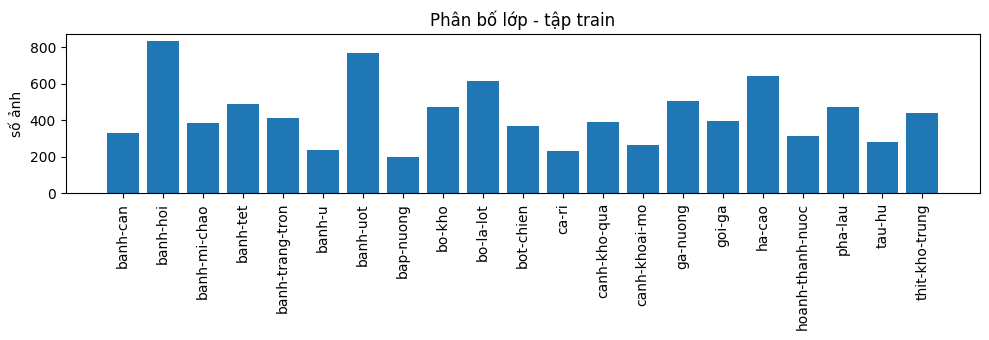

In [32]:
# Phân bố số ảnh mỗi lớp trên tập train
counts = np.bincount([_full.targets[i] for i in TRAIN_IDX], minlength=len(CLASSES))
plt.figure(figsize=(10, 3.5))
plt.bar(range(len(CLASSES)), counts)
plt.xticks(range(len(CLASSES)), CLASSES, rotation=90)
plt.ylabel("số ảnh"); plt.title("Phân bố lớp - tập train")
plt.tight_layout(); plt.show()

## Các hàm dùng chung: huấn luyện, đánh giá, vẽ kết quả

In [33]:
def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, running = 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += logits.argmax(1).cpu().tolist()
    return running / total, y_true, y_pred

def fit(model, train_dl, val_dl, epochs=20, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    # chỉ đưa tham số cần học vào optimizer (quan trọng với Bài 4)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_f1": [], "sec": []}
    best_f1, best_state = -1, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer)
        sec = time.time() - t0
        va_loss, yt, yp = evaluate(model, val_dl, criterion)
        va_f1 = f1_score(yt, yp, average="macro")
        for k, v in zip(hist, [tr_loss, va_loss, tr_acc, va_f1, sec]):
            hist[k].append(v)
        mark = ""
        if va_f1 > best_f1:            # giữ trọng số có F1 trên val tốt nhất
            best_f1, best_state = va_f1, copy.deepcopy(model.state_dict())
            mark = " *"
        print(f"epoch {ep:>2} | {sec:5.1f}s | train loss {tr_loss:.4f} acc {tr_acc:.4f}"
              f" | val loss {va_loss:.4f} F1 {va_f1:.4f}{mark}")
    model.load_state_dict(best_state)
    return model, hist

def test_report(model, test_dl, title):
    _, y_true, y_pred = evaluate(model, test_dl, nn.CrossEntropyLoss())
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    print(f"-- {title} (test) --")
    print(f"Accuracy         : {acc:.4f}")
    print(f"Precision (macro): {p:.4f}")
    print(f"Recall (macro)   : {r:.4f}")
    print(f"F1 (macro)       : {f1:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))
    return dict(acc=acc, precision=p, recall=r, f1=f1, y_true=y_true, y_pred=y_pred)

def plot_confusion(res, title):
    cm = confusion_matrix(res["y_true"], res["y_pred"], labels=range(len(CLASSES)))
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues", annot=True, fmt="d",
                annot_kws={"size": 7}, cbar=False)
    plt.xlabel("dự đoán"); plt.ylabel("nhãn thật"); plt.title(title)
    plt.tight_layout(); plt.show()

def plot_loss(hists, title):
    plt.figure(figsize=(7, 4))
    for name, h in hists.items():
        ep = range(1, len(h["train_loss"]) + 1)
        plt.plot(ep, h["train_loss"], "o-", ms=3, label=f"{name} - train")
        plt.plot(ep, h["val_loss"], "s--", ms=3, label=f"{name} - val")
    plt.xlabel("epoch"); plt.ylabel("cross-entropy"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

def show_shapes(model, img_size, names):
    x = torch.zeros(1, 3, img_size, img_size)
    model = model.cpu().eval()
    with torch.no_grad():
        print(f"{'input':<10}{str(tuple(x.shape)):<22}")
        for name in names:
            layer = getattr(model, name)
            x = layer(x)
            if x.dim() == 4 and name in ("gap", "pool"):
                x = x.flatten(1)
            print(f"{name:<10}{str(tuple(x.shape)):<22}{n_params(layer):>12,}")
    print(f"{'TỔNG':<32}{n_params(model):>12,}")

results = {}   # lưu kết quả để làm bảng tổng hợp cuối bài

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

![image.png](attachment:image.png)

In [34]:
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)
        with torch.no_grad():   # tính số chiều sau S4 bằng một lần forward giả
            n_flat = self.s4(self.c3(self.s2(self.c1(torch.zeros(1, in_ch, img, img))))).numel()
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

lenet = LeNet5(img=64, num_classes=len(CLASSES))
print(f"{'layer':<10}{'output':<22}{'tham số':>12}")
x = torch.zeros(1, 3, 64, 64)
for name in ["c1", "s2", "c3", "s4", "f5", "f6", "out"]:
    if name == "f5":
        x = x.flatten(1)
    x = getattr(lenet, name)(x)
    print(f"{name.upper():<10}{str(tuple(x.shape)):<22}{n_params(getattr(lenet, name)):>12,}")
print(f"{'TỔNG':<32}{n_params(lenet):>12,}")
assert n_params(lenet) == 339_421

layer     output                     tham số
C1        (1, 6, 60, 60)                 456
S2        (1, 6, 30, 30)                   0
C3        (1, 16, 26, 26)              2,416
S4        (1, 16, 13, 13)                  0
F5        (1, 120)                   324,600
F6        (1, 84)                     10,164
OUT       (1, 21)                      1,785
TỔNG                                 339,421


In [35]:
IMG1 = 64
train_dl, val_dl, test_dl = get_loaders(IMG1, augment=True)
xb, yb = next(iter(train_dl))
print("batch:", tuple(xb.shape), "| nhãn:", tuple(yb.shape))

batch: (32, 3, 64, 64) | nhãn: (32,)


In [36]:
# LeNet-5 với AvgPool2d
set_seed(42)
lenet_avg, hist_lenet_avg = fit(LeNet5(img=IMG1, num_classes=len(CLASSES), pool="avg"),
                                train_dl, val_dl, epochs=20, lr=1e-3)
res = test_report(lenet_avg, test_dl, "LeNet-5 AvgPool")
results["LeNet-5 (AvgPool)"] = dict(resize="64x64", params=n_params(lenet_avg),
                                    sec=np.mean(hist_lenet_avg["sec"]), **res)

epoch  1 |  17.3s | train loss 2.7940 acc 0.1545 | val loss 2.5670 F1 0.1249 *
epoch  2 |  18.4s | train loss 2.5771 acc 0.2103 | val loss 2.4552 F1 0.1634 *
epoch  3 |  23.3s | train loss 2.4857 acc 0.2397 | val loss 2.3490 F1 0.2154 *
epoch  4 |  17.5s | train loss 2.4199 acc 0.2606 | val loss 2.3567 F1 0.2242 *
epoch  5 |  17.7s | train loss 2.3752 acc 0.2680 | val loss 2.2763 F1 0.2381 *
epoch  6 |  17.4s | train loss 2.3164 acc 0.2879 | val loss 2.2537 F1 0.2554 *
epoch  7 |  17.8s | train loss 2.2652 acc 0.2988 | val loss 2.2812 F1 0.2714 *
epoch  8 |  17.6s | train loss 2.2171 acc 0.3104 | val loss 2.2149 F1 0.2634
epoch  9 |  17.5s | train loss 2.1725 acc 0.3264 | val loss 2.2131 F1 0.2753 *
epoch 10 |  17.5s | train loss 2.1263 acc 0.3417 | val loss 2.1356 F1 0.2906 *
epoch 11 |  17.1s | train loss 2.0936 acc 0.3523 | val loss 2.1225 F1 0.3133 *
epoch 12 |  17.4s | train loss 2.0480 acc 0.3656 | val loss 2.1084 F1 0.3324 *
epoch 13 |  17.2s | train loss 2.0263 acc 0.3784 | val

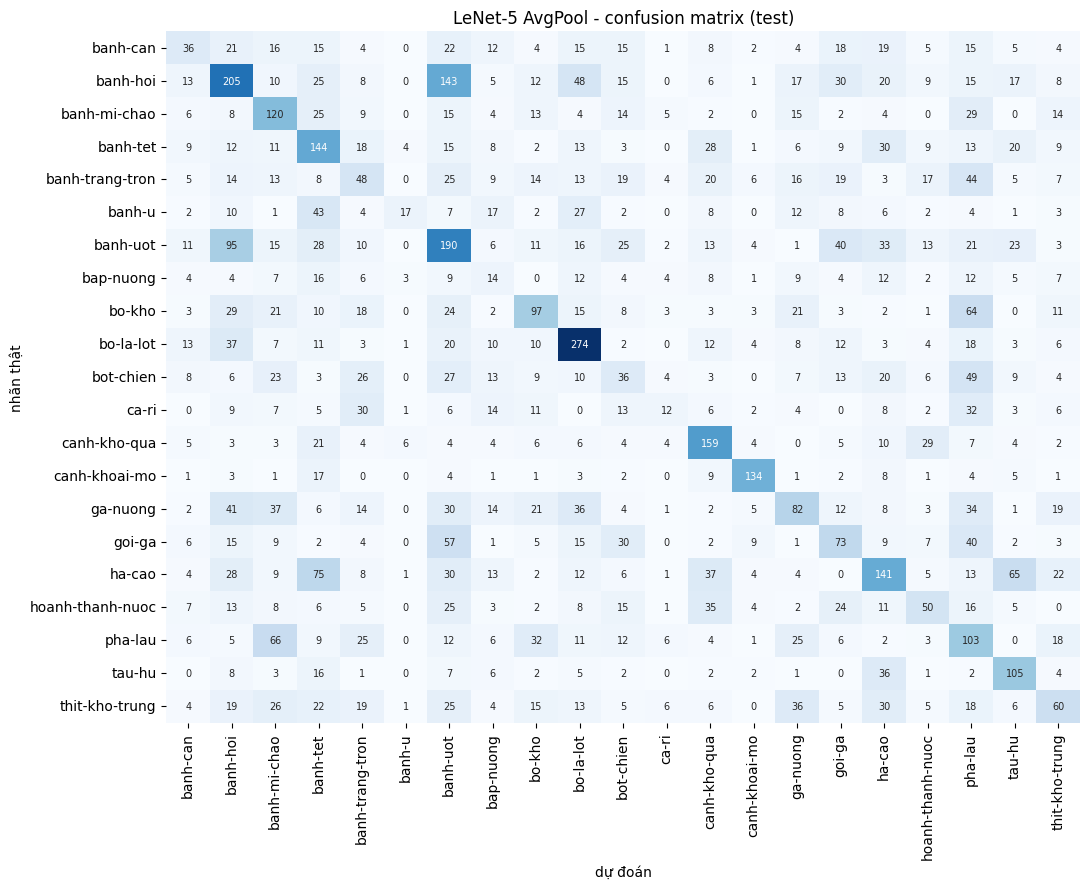

In [37]:
plot_confusion(results["LeNet-5 (AvgPool)"], "LeNet-5 AvgPool - confusion matrix (test)")

In [38]:
# Chạy lại với MaxPool2d, giữ nguyên mọi thứ khác
set_seed(42)
lenet_max, hist_lenet_max = fit(LeNet5(img=IMG1, num_classes=len(CLASSES), pool="max"),
                                train_dl, val_dl, epochs=20, lr=1e-3)
res = test_report(lenet_max, test_dl, "LeNet-5 MaxPool")
results["LeNet-5 (MaxPool)"] = dict(resize="64x64", params=n_params(lenet_max),
                                    sec=np.mean(hist_lenet_max["sec"]), **res)

epoch  1 |  17.5s | train loss 2.7996 acc 0.1514 | val loss 2.5775 F1 0.1221 *
epoch  2 |  17.4s | train loss 2.5811 acc 0.2124 | val loss 2.4319 F1 0.1738 *
epoch  3 |  17.1s | train loss 2.4530 acc 0.2476 | val loss 2.3204 F1 0.2360 *
epoch  4 |  17.3s | train loss 2.3800 acc 0.2725 | val loss 2.3179 F1 0.2205
epoch  5 |  17.0s | train loss 2.3285 acc 0.2840 | val loss 2.2429 F1 0.2627 *
epoch  6 |  17.1s | train loss 2.2619 acc 0.3093 | val loss 2.2400 F1 0.2957 *
epoch  7 |  16.9s | train loss 2.2062 acc 0.3251 | val loss 2.1979 F1 0.2778
epoch  8 |  16.7s | train loss 2.1682 acc 0.3284 | val loss 2.1847 F1 0.2801
epoch  9 |  17.4s | train loss 2.1257 acc 0.3407 | val loss 2.1248 F1 0.3023 *
epoch 10 |  17.4s | train loss 2.0991 acc 0.3507 | val loss 2.1313 F1 0.3189 *
epoch 11 |  17.5s | train loss 2.0520 acc 0.3696 | val loss 2.1008 F1 0.3056
epoch 12 |  17.4s | train loss 2.0316 acc 0.3700 | val loss 2.0837 F1 0.3457 *
epoch 13 |  17.3s | train loss 2.0154 acc 0.3742 | val loss 

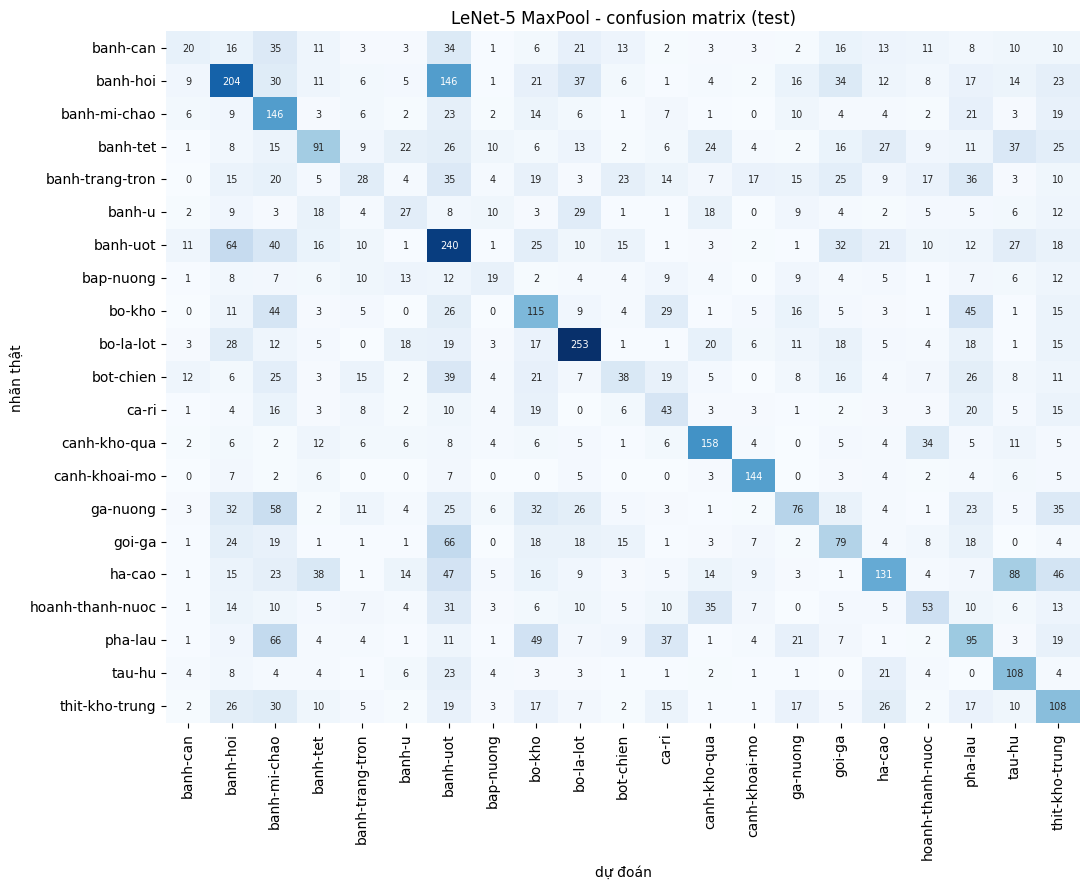

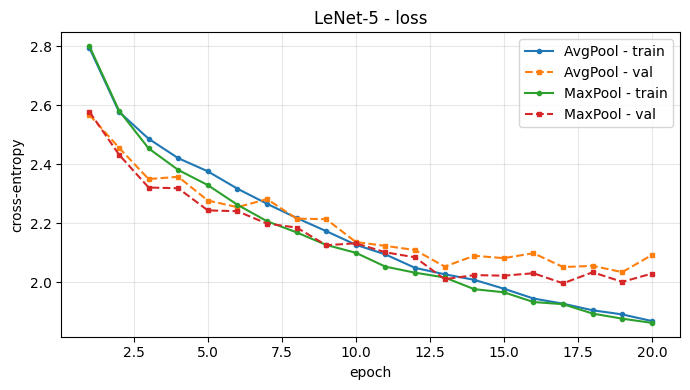

,F1 AvgPool,F1 MaxPool
banh-can,0.1865,0.1242
banh-hoi,0.3440,0.3611
banh-mi-chao,0.3419,0.3259
banh-tet,0.3307,0.2931
banh-trang-tron,0.1675,0.1247
banh-u,0.1619,0.1725
banh-uot,0.3023,0.3392
bap-nuong,0.0906,0.1667
bo-kho,0.3186,0.3054
bo-la-lot,0.5404,0.5383


In [39]:
plot_confusion(results["LeNet-5 (MaxPool)"], "LeNet-5 MaxPool - confusion matrix (test)")
plot_loss({"AvgPool": hist_lenet_avg, "MaxPool": hist_lenet_max}, "LeNet-5 - loss")

# F1 từng lớp của hai bản
f1_avg = f1_score(results["LeNet-5 (AvgPool)"]["y_true"], results["LeNet-5 (AvgPool)"]["y_pred"], average=None)
f1_max = f1_score(results["LeNet-5 (MaxPool)"]["y_true"], results["LeNet-5 (MaxPool)"]["y_pred"], average=None)
pd.DataFrame({"F1 AvgPool": f1_avg, "F1 MaxPool": f1_max}, index=CLASSES).round(4)

**Nhận xét Bài 1:**

- Mô hình LeNet có tổng cộng 339,421 tham số, đúng với kết quả tính tay. Phần lớn tham số nằm ở lớp F5 (324,600), còn 2 lớp conv chỉ có 2,872 tham số.
- Kết quả trên tập test còn khá thấp: bản dùng AvgPool đạt accuracy 0.3143 và macro-F1 0.2931, bản dùng MaxPool đạt accuracy 0.3257 và macro-F1 0.3045. MaxPool tốt hơn một chút nhưng không đáng kể (khoảng 0.01).
- Sau 20 epoch thì train loss vẫn còn khoảng 1.87 và train acc chỉ khoảng 0.41, nên mô hình đang bị underfit. Theo em là do LeNet quá nhỏ (chỉ có 2 lớp conv với 6 và 16 filter), trong khi bài toán có tới 21 lớp món ăn nhìn khá giống nhau.
- Lớp làm tốt nhất là canh-khoai-mo (F1 khoảng 0.69) và bo-la-lot (khoảng 0.54), có thể vì màu của 2 món này dễ nhận ra. Các lớp như bap-nuong, banh-can, ca-ri thì F1 chỉ khoảng 0.1 - 0.2.

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

![image.png](attachment:image.png)

**GoogLeNet (Multi-branch Network)**

![image-2.png](attachment:image-2.png)

In [40]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
                                nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
                                nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1),
                                nn.Conv2d(in_ch, fp, 1), nn.ReLU())
        self.out_ch = f1 + f3 + f5 + fp

    def forward(self, x):
        # nối 4 nhánh theo chiều channel (dim=1 vì tensor là N, C, H, W)
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)


class GoogLeNetMini(nn.Module):
    # bản rút gọn: stem + 4 Inception block, không có auxiliary classifier
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2))                                   # 64 -> 32
        self.inc1 = InceptionBlock(64, 32, 48, 64, 8, 16, 16)    # 32+64+16+16  = 128
        self.inc2 = InceptionBlock(128, 64, 64, 96, 16, 32, 32)  # 64+96+32+32  = 224
        self.pool1 = nn.MaxPool2d(2, 2)                          # 32 -> 16
        self.inc3 = InceptionBlock(224, 96, 64, 128, 16, 32, 32) # 96+128+32+32 = 288
        self.pool2 = nn.MaxPool2d(2, 2)                          # 16 -> 8
        self.inc4 = InceptionBlock(288, 128, 96, 192, 24, 64, 64)# 128+192+64+64 = 448
        self.gap = nn.AdaptiveAvgPool2d(1)                       # thay cho Flatten
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(448, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.inc2(self.inc1(x))
        x = self.inc3(self.pool1(x))
        x = self.inc4(self.pool2(x))
        x = self.gap(x).flatten(1)
        return self.fc(self.dropout(x))

gnet = GoogLeNetMini(num_classes=len(CLASSES))
print(f"{'layer':<10}{'output shape':<22}{'tham số':>12}")
show_shapes(gnet, 64, ["stem", "inc1", "inc2", "pool1", "inc3", "pool2", "inc4", "gap", "fc"])
print()
for name in ["inc1", "inc2", "inc3", "inc4"]:
    print(f"{name}: channel ra tính tay = {getattr(gnet, name).out_ch}")

layer     output shape               tham số
input     (1, 3, 64, 64)        
stem      (1, 64, 32, 32)              1,920
inc1      (1, 128, 32, 32)            37,688
inc2      (1, 224, 32, 32)            90,928
pool1     (1, 224, 16, 16)                 0
inc3      (1, 288, 16, 16)           133,488
pool2     (1, 288, 8, 8)                   0
inc4      (1, 448, 8, 8)             294,712
gap       (1, 448)                         0
fc        (1, 21)                      9,429
TỔNG                                 568,165

inc1: channel ra tính tay = 128
inc2: channel ra tính tay = 224
inc3: channel ra tính tay = 288
inc4: channel ra tính tay = 448


In [41]:
set_seed(42)
gnet, hist_gnet = fit(GoogLeNetMini(num_classes=len(CLASSES)), train_dl, val_dl, epochs=20, lr=1e-3)
res = test_report(gnet, test_dl, "GoogLeNet rút gọn")
results["GoogLeNet rút gọn"] = dict(resize="64x64", params=n_params(gnet),
                                    sec=np.mean(hist_gnet["sec"]), **res)

epoch  1 |  19.8s | train loss 2.9032 acc 0.1105 | val loss 2.6570 F1 0.1087 *
epoch  2 |  20.0s | train loss 2.6285 acc 0.1846 | val loss 2.4128 F1 0.1670 *
epoch  3 |  19.7s | train loss 2.4721 acc 0.2389 | val loss 2.3206 F1 0.2229 *
epoch  4 |  20.0s | train loss 2.3259 acc 0.2804 | val loss 2.1674 F1 0.2651 *
epoch  5 |  19.7s | train loss 2.2183 acc 0.3146 | val loss 2.1377 F1 0.2883 *
epoch  6 |  19.7s | train loss 2.1465 acc 0.3324 | val loss 2.0209 F1 0.3335 *
epoch  7 |  19.9s | train loss 2.0689 acc 0.3645 | val loss 2.0049 F1 0.3365 *
epoch  8 |  19.8s | train loss 1.9840 acc 0.3856 | val loss 1.8764 F1 0.3760 *
epoch  9 |  20.0s | train loss 1.9271 acc 0.3956 | val loss 1.8399 F1 0.3822 *
epoch 10 |  20.1s | train loss 1.8775 acc 0.4107 | val loss 1.7496 F1 0.4257 *
epoch 11 |  19.9s | train loss 1.8181 acc 0.4282 | val loss 1.7148 F1 0.4191
epoch 12 |  19.7s | train loss 1.7580 acc 0.4502 | val loss 1.6971 F1 0.4231
epoch 13 |  19.8s | train loss 1.7281 acc 0.4652 | val l

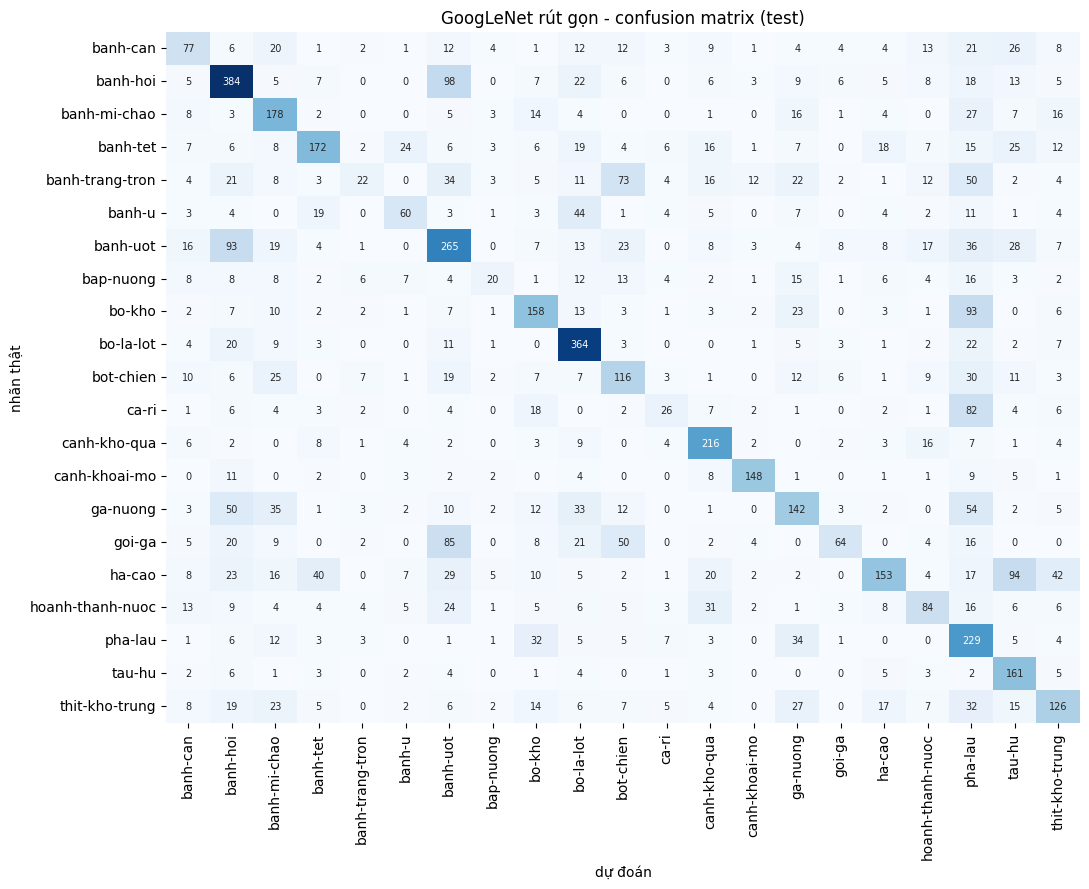

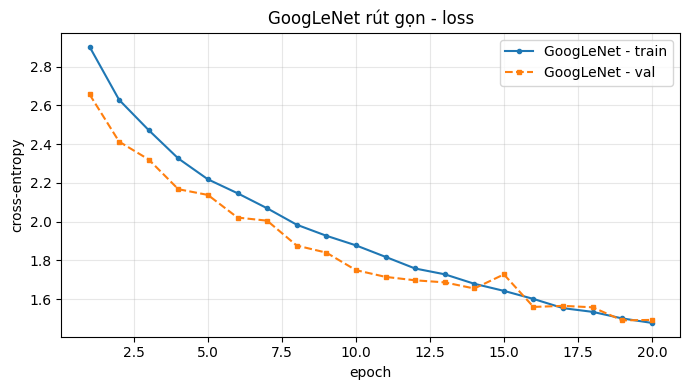

,tham số,giây/epoch,accuracy,macro-F1
LeNet-5 (AvgPool),"339,421",17.7,0.3143,0.2931
LeNet-5 (MaxPool),"339,421",17.3,0.3257,0.3045
GoogLeNet rút gọn,"568,165",19.9,0.4737,0.4402


In [42]:
plot_confusion(results["GoogLeNet rút gọn"], "GoogLeNet rút gọn - confusion matrix (test)")
plot_loss({"GoogLeNet": hist_gnet}, "GoogLeNet rút gọn - loss")

# So sánh với Bài 1
pd.DataFrame({k: {"tham số": f"{v['params']:,}", "giây/epoch": round(v["sec"], 1),
                  "accuracy": round(v["acc"], 4), "macro-F1": round(v["f1"], 4)}
              for k, v in results.items()}).T

**Nhận xét Bài 2:**

- Em dùng 4 Inception block, số channel đầu ra của từng block là 128, 224, 288, 448. Kết quả tính tay và in ra từ code giống nhau.
- Tổng số tham số là 568,165, nhiều hơn LeNet khoảng 1.7 lần. Thời gian train mỗi epoch là 19.9s, chỉ chậm hơn LeNet (khoảng 17.5s) một chút.
- Kết quả tốt hơn Bài 1 khá nhiều: accuracy 0.4737, macro-F1 0.4402 (LeNet chỉ khoảng 0.30). Lý do là mỗi Inception block dùng nhiều kích thước kernel cùng lúc (1x1, 3x3, 5x5) nên lấy được đặc trưng ở nhiều mức khác nhau, và mạng cũng sâu hơn LeNet.
- Do dùng Global Average Pooling thay cho Flatten nên lớp fully connected cuối chỉ còn 9,429 tham số.
- Tới epoch 20 val loss vẫn còn giảm, nên nếu train thêm vài epoch thì kết quả có thể còn tăng.

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

![image.png](attachment:image.png)

**ResNet**

![image-2.png](attachment:image-2.png)

In [43]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:   # đổi shape thì dùng projection 1x1 + BN
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))   # cộng trước, ReLU sau


class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, 1)
        self.layer2 = self._stage(64, 128, 2)
        self.layer3 = self._stage(128, 256, 2)
        self.layer4 = self._stage(256, 512, 2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride), BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.fc(self.pool(x).flatten(1))

IMG3 = 96
r18 = ResNet18(num_classes=len(CLASSES))
print(f"{'stage':<10}{'output shape':<22}{'tham số':>12}")
show_shapes(r18, IMG3, ["stem", "layer1", "layer2", "layer3", "layer4", "pool", "fc"])

# đối chiếu với resnet18 của torchvision
from torchvision.models import resnet18
tv = resnet18(weights=None)
tv.fc = nn.Linear(512, len(CLASSES))
print("\ntorchvision resnet18 (21 lớp):", f"{n_params(tv):,}")
assert n_params(tv) == n_params(r18)

stage     output shape               tham số
input     (1, 3, 96, 96)        
stem      (1, 64, 24, 24)              9,536
layer1    (1, 64, 24, 24)            147,968
layer2    (1, 128, 12, 12)           525,568
layer3    (1, 256, 6, 6)           2,099,712
layer4    (1, 512, 3, 3)           8,393,728
pool      (1, 512)                         0
fc        (1, 21)                     10,773
TỔNG                              11,187,285

torchvision resnet18 (21 lớp): 11,187,285


In [44]:
# Lần 1: có augmentation
train_dl3, val_dl3, test_dl3 = get_loaders(IMG3, augment=True)
set_seed(42)
r18_aug, hist_r18_aug = fit(ResNet18(num_classes=len(CLASSES)), train_dl3, val_dl3, epochs=20, lr=1e-3)
res = test_report(r18_aug, test_dl3, "ResNet-18 có augmentation")
results["ResNet-18 (có augment)"] = dict(resize=f"{IMG3}x{IMG3}", params=n_params(r18_aug),
                                         sec=np.mean(hist_r18_aug["sec"]), **res)

epoch  1 |  23.6s | train loss 2.7690 acc 0.1647 | val loss 2.6319 F1 0.1564 *
epoch  2 |  23.3s | train loss 2.4681 acc 0.2441 | val loss 2.4299 F1 0.2201 *
epoch  3 |  23.8s | train loss 2.3315 acc 0.2852 | val loss 2.2198 F1 0.2349 *
epoch  4 |  23.7s | train loss 2.1878 acc 0.3238 | val loss 2.1821 F1 0.2928 *
epoch  5 |  23.5s | train loss 2.0831 acc 0.3592 | val loss 2.1324 F1 0.3035 *
epoch  6 |  23.6s | train loss 1.9700 acc 0.3819 | val loss 2.0084 F1 0.3096 *
epoch  7 |  23.6s | train loss 1.9114 acc 0.4024 | val loss 1.9356 F1 0.3584 *
epoch  8 |  23.7s | train loss 1.8327 acc 0.4219 | val loss 2.0061 F1 0.3533
epoch  9 |  23.6s | train loss 1.7426 acc 0.4543 | val loss 1.7009 F1 0.4272 *
epoch 10 |  23.4s | train loss 1.6562 acc 0.4778 | val loss 1.6885 F1 0.4324 *
epoch 11 |  23.8s | train loss 1.5837 acc 0.5014 | val loss 1.9065 F1 0.4043
epoch 12 |  23.7s | train loss 1.5140 acc 0.5198 | val loss 1.7051 F1 0.4399 *
epoch 13 |  23.4s | train loss 1.4647 acc 0.5373 | val l

In [45]:
# Lần 2: không augmentation (tập train dùng transform giống val/test)
train_dl3n, _, _ = get_loaders(IMG3, augment=False)
set_seed(42)
r18_noaug, hist_r18_noaug = fit(ResNet18(num_classes=len(CLASSES)), train_dl3n, val_dl3, epochs=20, lr=1e-3)
res = test_report(r18_noaug, test_dl3, "ResNet-18 không augmentation")
results["ResNet-18 (không augment)"] = dict(resize=f"{IMG3}x{IMG3}", params=n_params(r18_noaug),
                                            sec=np.mean(hist_r18_noaug["sec"]), **res)

epoch  1 |  16.5s | train loss 2.6551 acc 0.1966 | val loss 2.7278 F1 0.1439 *
epoch  2 |  16.3s | train loss 2.3418 acc 0.2765 | val loss 2.3973 F1 0.2084 *
epoch  3 |  16.8s | train loss 2.1534 acc 0.3393 | val loss 2.4200 F1 0.2321 *
epoch  4 |  16.4s | train loss 1.9657 acc 0.3883 | val loss 1.9901 F1 0.3341 *
epoch  5 |  16.5s | train loss 1.8128 acc 0.4310 | val loss 1.8823 F1 0.3558 *
epoch  6 |  16.7s | train loss 1.6066 acc 0.4950 | val loss 1.9200 F1 0.3664 *
epoch  7 |  16.6s | train loss 1.3959 acc 0.5596 | val loss 1.8605 F1 0.4342 *
epoch  8 |  16.9s | train loss 1.1444 acc 0.6259 | val loss 1.9201 F1 0.4170
epoch  9 |  16.1s | train loss 0.8226 acc 0.7342 | val loss 2.0705 F1 0.4360 *
epoch 10 |  16.7s | train loss 0.5400 acc 0.8225 | val loss 1.9994 F1 0.4775 *
epoch 11 |  16.5s | train loss 0.3191 acc 0.8975 | val loss 2.4062 F1 0.4307
epoch 12 |  16.3s | train loss 0.2325 acc 0.9227 | val loss 2.4143 F1 0.4744
epoch 13 |  16.5s | train loss 0.1657 acc 0.9456 | val los

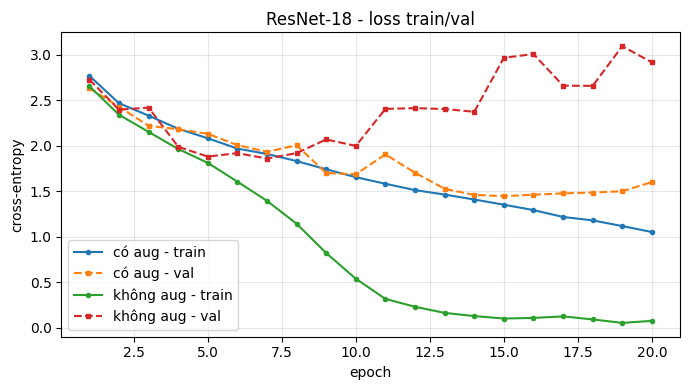

có augment    : val loss thấp nhất ở epoch 15 (1.4477), train loss cuối 1.0536
không augment : val loss thấp nhất ở epoch 7 (1.8605), train loss cuối 0.0780

Chênh lệch macro-F1 (có aug - không aug): +0.0311


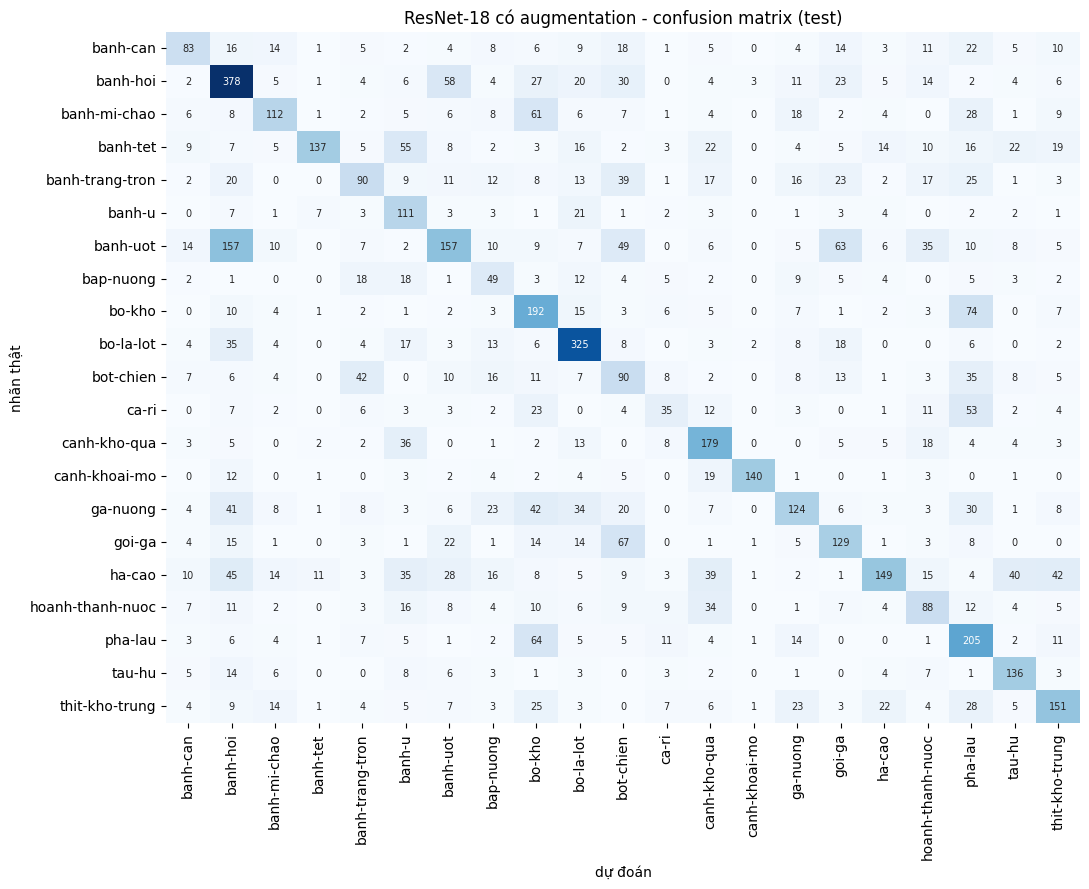

In [46]:
plot_loss({"có aug": hist_r18_aug, "không aug": hist_r18_noaug}, "ResNet-18 - loss train/val")

# epoch val loss thấp nhất = lúc hai đường bắt đầu tách nhau
for name, h in [("có augment", hist_r18_aug), ("không augment", hist_r18_noaug)]:
    ep = int(np.argmin(h["val_loss"])) + 1
    print(f"{name:<14}: val loss thấp nhất ở epoch {ep} ({min(h['val_loss']):.4f}), "
          f"train loss cuối {h['train_loss'][-1]:.4f}")

d = results["ResNet-18 (có augment)"]["f1"] - results["ResNet-18 (không augment)"]["f1"]
print(f"\nChênh lệch macro-F1 (có aug - không aug): {d:+.4f}")
plot_confusion(results["ResNet-18 (có augment)"], "ResNet-18 có augmentation - confusion matrix (test)")

**Nhận xét Bài 3:**

- ResNet-18 có 11,187,285 tham số, bằng với resnet18 của torchvision khi đổi lớp cuối thành 21 lớp.
- Lần chạy có augmentation: macro-F1 0.4487, accuracy 0.4579. Val loss thấp nhất ở epoch 15 (1.4477), sau đó train loss vẫn giảm nhưng val loss tăng lại, nên khoảng từ epoch 15 thì 2 đường bắt đầu tách nhau.
- Lần chạy không augmentation: macro-F1 0.4176, accuracy 0.4307. Val loss thấp nhất ở epoch 7 (1.8605). Sau đó train acc tăng lên gần 0.97 còn val loss tăng lên gần 3.0, tức là mô hình bị overfit rất nặng.
- Augmentation giúp macro-F1 tăng thêm 0.0311 và làm mô hình overfit chậm hơn (từ epoch 7 lùi ra epoch 15).
- ResNet-18 có số tham số gấp khoảng 20 lần GoogLeNet nhưng kết quả chỉ ngang nhau (0.4487 so với 0.4402). Theo em là do tập train chỉ có khoảng 9 nghìn ảnh, quá ít so với 11 triệu tham số, nên khi train từ đầu mô hình rất dễ bị overfit.

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

In [47]:
from transformers import ResNetForImageClassification
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars

hf_logging.disable_progress_bar()   # tắt thanh tiến trình khi tải model
disable_progress_bars()

class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)
        if freeze_backbone:                  # feature extraction: đóng băng backbone
            for p in self.resnet.parameters():
                p.requires_grad = False

    def forward(self, images):
        features = self.resnet(images).pooler_output      # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1)       # [B, 2048]
        return self.classifier(features)                  # [B, 21]

m = PretrainedResnet(len(CLASSES), freeze_backbone=True)
print("tổng tham số   :", f"{n_params(m):,}")
print("tham số được học:", f"{n_params(m, trainable_only=True):,}")
del m

tổng tham số   : 23,551,061
tham số được học: 43,029


In [48]:
IMG4 = 224
EPOCHS4 = 5     # model đã pretrained nên vài epoch là đủ
train_dl4, val_dl4, test_dl4 = get_loaders(IMG4, batch_size=32, augment=True)

# Chế độ 1: feature extraction, chỉ học classifier, lr = 1e-3
set_seed(42)
r50_fe, hist_r50_fe = fit(PretrainedResnet(len(CLASSES), freeze_backbone=True),
                          train_dl4, val_dl4, epochs=EPOCHS4, lr=1e-3)
res = test_report(r50_fe, test_dl4, "ResNet-50 feature extraction")
results["ResNet-50 (feature extraction)"] = dict(resize="224x224", params=n_params(r50_fe),
                                                 sec=np.mean(hist_r50_fe["sec"]), **res)

epoch  1 |  50.9s | train loss 2.4729 acc 0.3147 | val loss 2.1826 F1 0.4694 *
epoch  2 |  51.2s | train loss 1.8970 acc 0.5110 | val loss 1.9030 F1 0.5073 *
epoch  3 |  50.9s | train loss 1.6284 acc 0.5707 | val loss 1.6851 F1 0.5551 *
epoch  4 |  51.2s | train loss 1.4774 acc 0.5926 | val loss 1.5829 F1 0.5795 *
epoch  5 |  51.7s | train loss 1.3862 acc 0.6163 | val loss 1.5190 F1 0.5999 *
-- ResNet-50 feature extraction (test) --
Accuracy         : 0.5310
Precision (macro): 0.5789
Recall (macro)   : 0.5343
F1 (macro)       : 0.5321

                  precision    recall  f1-score   support

        banh-can     0.5399    0.5892    0.5635       241
        banh-hoi     0.6613    0.3377    0.4471       607
    banh-mi-chao     0.5376    0.6920    0.6051       289
        banh-tet     0.8750    0.4615    0.6043       364
 banh-trang-tron     0.6634    0.4401    0.5292       309
          banh-u     0.7928    0.5000    0.6132       176
        banh-uot     0.5413    0.3393    0.4171    

In [49]:
# Chế độ 2: fine-tuning toàn mạng, lr nhỏ hơn = 1e-4
set_seed(42)
r50_ft, hist_r50_ft = fit(PretrainedResnet(len(CLASSES), freeze_backbone=False),
                          train_dl4, val_dl4, epochs=EPOCHS4, lr=1e-4)
res = test_report(r50_ft, test_dl4, "ResNet-50 fine-tuning")
results["ResNet-50 (fine-tuning)"] = dict(resize="224x224", params=n_params(r50_ft),
                                          sec=np.mean(hist_r50_ft["sec"]), **res)

epoch  1 | 105.2s | train loss 2.7495 acc 0.1799 | val loss 2.2847 F1 0.3186 *
epoch  2 | 105.5s | train loss 1.6707 acc 0.5539 | val loss 1.1186 F1 0.6582 *
epoch  3 | 105.5s | train loss 0.9779 acc 0.7138 | val loss 0.7247 F1 0.7688 *
epoch  4 | 105.3s | train loss 0.7121 acc 0.7832 | val loss 0.5736 F1 0.8150 *
epoch  5 | 105.8s | train loss 0.5664 acc 0.8281 | val loss 0.5121 F1 0.8280 *
-- ResNet-50 fine-tuning (test) --
Accuracy         : 0.7930
Precision (macro): 0.8013
Recall (macro)   : 0.7905
F1 (macro)       : 0.7857

                  precision    recall  f1-score   support

        banh-can     0.7138    0.9212    0.8043       241
        banh-hoi     0.7681    0.8567    0.8100       607
    banh-mi-chao     0.8682    0.8893    0.8786       289
        banh-tet     0.9592    0.7747    0.8571       364
 banh-trang-tron     0.9106    0.6926    0.7868       309
          banh-u     0.8430    0.8239    0.8333       176
        banh-uot     0.8190    0.6143    0.7020       560


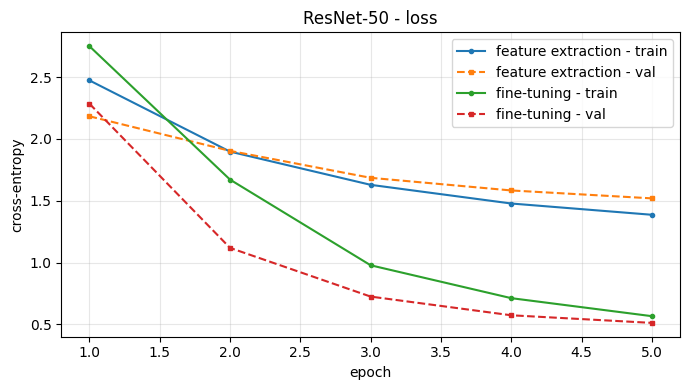

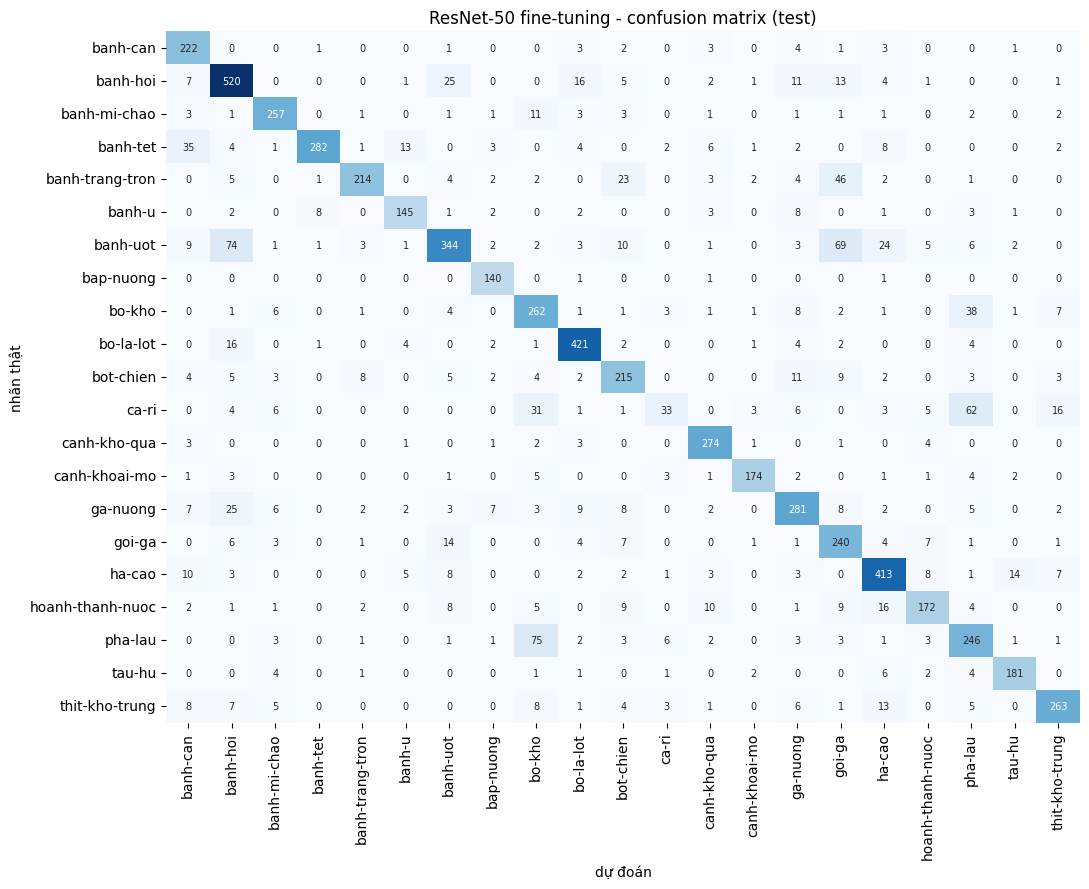

In [50]:
plot_loss({"feature extraction": hist_r50_fe, "fine-tuning": hist_r50_ft}, "ResNet-50 - loss")
plot_confusion(results["ResNet-50 (fine-tuning)"], "ResNet-50 fine-tuning - confusion matrix (test)")

**Nhận xét Bài 4:**

- Feature extraction (đóng băng backbone, chỉ train lớp classifier với 43,029 tham số, lr = 1e-3): macro-F1 0.5321, accuracy 0.5310. Ngay epoch đầu tiên val F1 đã đạt 0.4694, gần bằng ResNet-18 train từ đầu sau 15 epoch.
- Fine-tuning (train toàn bộ 23,551,061 tham số, lr = 1e-4): macro-F1 0.7857, accuracy 0.7930, cao nhất trong tất cả các mô hình. Mỗi epoch mất khoảng 105s, gấp đôi feature extraction vì phải cập nhật cả backbone.
- Fine-tuning tốt hơn feature extraction khoảng 0.25 F1. Đặc trưng học từ ImageNet có ích nhưng chưa phù hợp hoàn toàn với món ăn Việt Nam, nên khi cho backbone học thêm với lr nhỏ thì kết quả tăng lên nhiều.
- So với ResNet-18 train từ đầu ở Bài 3 (0.4487) thì ResNet-50 fine-tuning cao hơn khoảng 0.34. Lý do là model pretrained đã học được các đặc trưng cơ bản (cạnh, màu, kết cấu) từ ImageNet, còn ResNet-18 ở Bài 3 phải học lại từ đầu với ít dữ liệu.
- Nhìn confusion matrix thì lớp bị nhầm nhiều nhất là ca-ri (F1 chỉ 0.296): 62 ảnh bị đoán thành pha-lau, 31 ảnh thành bo-kho. Ngoài ra pha-lau với bo-kho cũng hay bị nhầm qua lại, banh-uot hay bị nhầm thành banh-hoi và goi-ga. Các món này có màu và cách bày khá giống nhau nên bị nhầm cũng dễ hiểu.

## Bảng tổng hợp kết quả

In [51]:
summary = pd.DataFrame([{
    "Mô hình": k, "Resize": v["resize"], "Tham số": f"{v['params']:,}",
    "Giây/epoch": round(v["sec"], 1), "Accuracy": round(v["acc"], 4),
    "Precision": round(v["precision"], 4), "Recall": round(v["recall"], 4),
    "macro-F1": round(v["f1"], 4)} for k, v in results.items()])
summary

,Mô hình,Resize,Tham số,Giây/epoch,Accuracy,Precision,Recall,macro-F1
0,LeNet-5 (AvgPool),64x64,"339,421",17.7,0.3143,0.3145,0.2984,0.2931
1,LeNet-5 (MaxPool),64x64,"339,421",17.3,0.3257,0.3167,0.3161,0.3045
2,GoogLeNet rút gọn,64x64,"568,165",19.9,0.4737,0.4830,0.4521,0.4402
3,ResNet-18 (có augment),96x96,"11,187,285",23.5,0.4579,0.4775,0.4562,0.4487
4,ResNet-18 (không augment),96x96,"11,187,285",16.5,0.4307,0.4371,0.4199,0.4176
5,ResNet-50 (feature extraction),224x224,"23,551,061",51.2,0.5310,0.5789,0.5343,0.5321
6,ResNet-50 (fine-tuning),224x224,"23,551,061",105.4,0.7930,0.8013,0.7905,0.7857


In [52]:
# F1 từng lớp của tất cả mô hình, để xem lớp nào khó
f1_table = pd.DataFrame({k: f1_score(v["y_true"], v["y_pred"], average=None,
                                     labels=range(len(CLASSES)), zero_division=0)
                         for k, v in results.items()}, index=CLASSES).round(3)
f1_table.style.background_gradient(cmap="RdYlGn", axis=None)

,LeNet-5 (AvgPool),LeNet-5 (MaxPool),GoogLeNet rút gọn,ResNet-18 (có augment),ResNet-18 (không augment),ResNet-50 (feature extraction),ResNet-50 (fine-tuning)
banh-can,0.187000,0.124000,0.356000,0.405000,0.294000,0.563000,0.804000
banh-hoi,0.344000,0.361000,0.583000,0.534000,0.460000,0.447000,0.810000
banh-mi-chao,0.342000,0.326000,0.521000,0.449000,0.429000,0.605000,0.879000
banh-tet,0.331000,0.293000,0.531000,0.518000,0.437000,0.604000,0.857000
banh-trang-tron,0.168000,0.125000,0.120000,0.342000,0.327000,0.529000,0.787000
banh-u,0.162000,0.173000,0.407000,0.429000,0.333000,0.613000,0.833000
banh-uot,0.302000,0.339000,0.445000,0.347000,0.412000,0.417000,0.702000
bap-nuong,0.091000,0.167000,0.206000,0.297000,0.228000,0.741000,0.915000
bo-kho,0.319000,0.305000,0.486000,0.449000,0.406000,0.475000,0.699000
bo-la-lot,0.540000,0.538000,0.679000,0.653000,0.596000,0.511000,0.899000


## Kết luận

| Mô hình | Resize | Tham số | Giây/epoch | Accuracy | macro-F1 |
|---|---|---|---|---|---|
| LeNet-5 (AvgPool) | 64x64 | 339,421 | 17.7 | 0.3143 | 0.2931 |
| LeNet-5 (MaxPool) | 64x64 | 339,421 | 17.3 | 0.3257 | 0.3045 |
| GoogLeNet rút gọn | 64x64 | 568,165 | 19.9 | 0.4737 | 0.4402 |
| ResNet-18 (có augment) | 96x96 | 11,187,285 | 23.5 | 0.4579 | 0.4487 |
| ResNet-18 (không augment) | 96x96 | 11,187,285 | 16.5 | 0.4307 | 0.4176 |
| ResNet-50 (feature extraction) | 224x224 | 23,551,061 | 51.2 | 0.5310 | 0.5321 |
| ResNet-50 (fine-tuning) | 224x224 | 23,551,061 | 105.4 | 0.7930 | 0.7857 |

- Khi train từ đầu, GoogLeNet và ResNet-18 (có augmentation) cho kết quả tốt hơn LeNet rõ rệt (khoảng 0.44 - 0.45 so với 0.30). Tuy nhiên ResNet-18 nhiều tham số hơn hẳn mà không tốt hơn GoogLeNet bao nhiêu, do dữ liệu ít. Augmentation giúp giảm overfit khá rõ.
- Dùng transfer learning (ResNet-50 pretrained + fine-tuning) cho kết quả tốt nhất với macro-F1 0.7857, cao hơn nhiều so với các mô hình train từ đầu. Với bộ dữ liệu không quá lớn như VinaFood21 thì nên dùng mô hình pretrained.
- ca-ri là lớp khó nhất ở hầu hết các mô hình, còn canh-khoai-mo và bo-la-lot là các lớp dễ nhất.